In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:


!pip install timm --quiet

import os, json, random, shutil, time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import timm
from timm.data.mixup import Mixup
from timm.loss import SoftTargetCrossEntropy
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, top_k_accuracy_score
)
from tqdm import tqdm
from collections import defaultdict
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.manifold import TSNE

import cv2
import torch.nn.functional as F
from PIL import Image
import matplotlib as mpl
import gradio as gr

print(" All libraries imported successfully!")
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")

 All libraries imported successfully!
PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4


In [ ]:
# ============================================================
# CELL 2 — Set Paths
# ============================================================

SOURCE_DIR = '/content/drive/MyDrive/color'
# All generated files go here (inside Colab's local storage, fast I/O)
WORK_DIR   = '/content/swin_plantvillage'
SPLIT_DIR  = os.path.join(WORK_DIR, 'data_split')
CKPT_DIR   = os.path.join(WORK_DIR, 'checkpoints')
os.makedirs(WORK_DIR,  exist_ok=True)
os.makedirs(CKPT_DIR,  exist_ok=True)

# ── Training hyperparameters ────────────────────────────────
IMG_SIZE        = 224
BATCH_SIZE      = 64    # Colab T4 handles 64 fine; lower to 32 if OOM
NUM_EPOCHS      = 18
LR              = 1e-4
WEIGHT_DECAY    = 0.05
WARMUP_EPOCHS   = 5
NUM_WORKERS     = 2
SEED            = 42
MIXUP_ALPHA     = 0.8
CUTMIX_ALPHA    = 1.0
MIXUP_PROB      = 1.0
MIXUP_SWITCH_PROB = 0.5
LABEL_SMOOTHING = 0.1

# Verify source dataset exists
assert os.path.exists(SOURCE_DIR), (
    f"\n Dataset not found at: {SOURCE_DIR}\n"
    f"   Please update SOURCE_DIR in this cell."
)
classes_found = [d for d in os.listdir(SOURCE_DIR)
                 if os.path.isdir(os.path.join(SOURCE_DIR, d))]
print(f" Dataset found — {len(classes_found)} classes at:\n   {SOURCE_DIR}")

 Dataset found — 38 classes at:
   /content/drive/MyDrive/color


Splitting 38 classes into train / val / test …
  [10/38] done
  [20/38] done
  [30/38] done
  [38/38] done

 Split complete! Train=37817 | Val=8091 | Test=8140


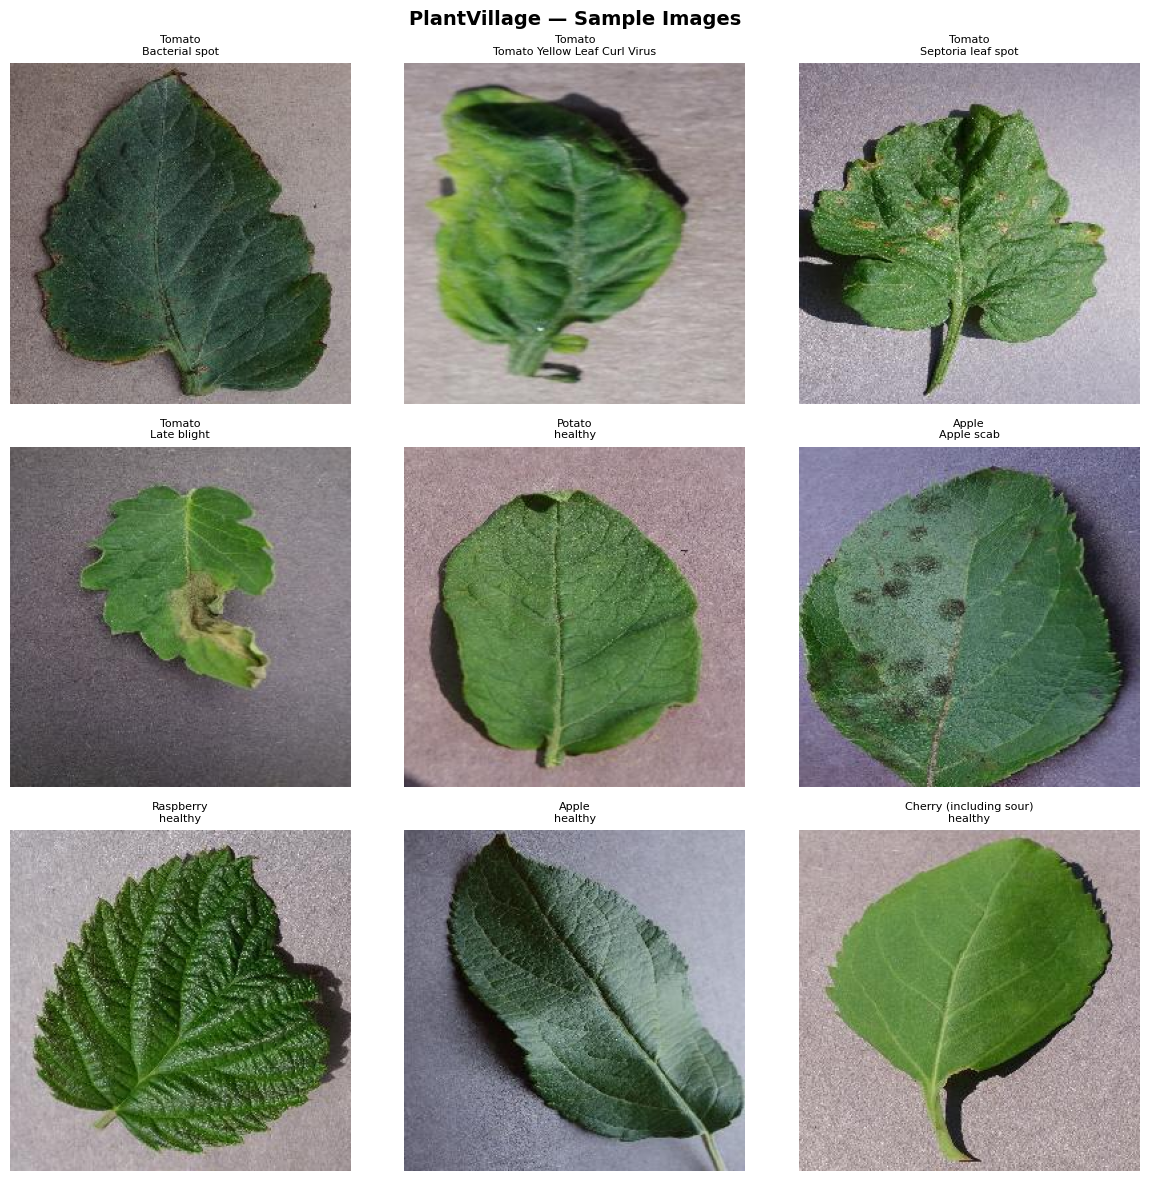

 Sample images shown above & saved.


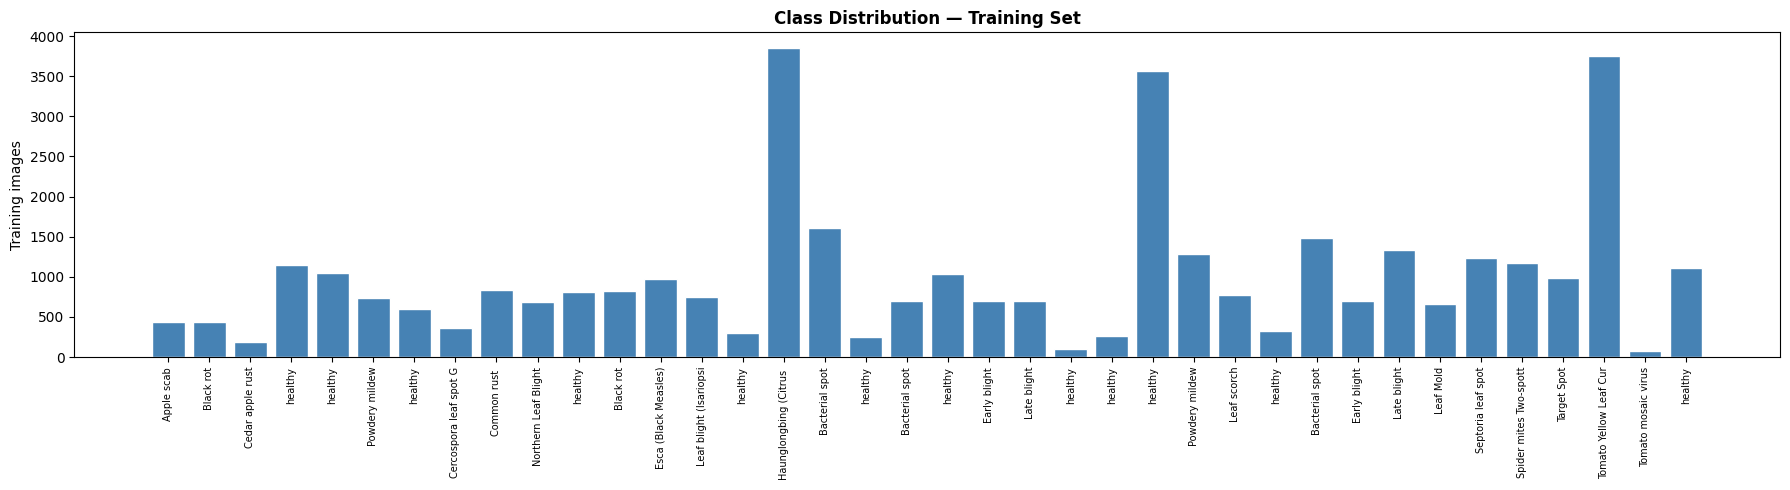

 Class distribution shown above & saved.

Total classes: 38


In [ ]:


# ============================================================
# CELL 3 — Prepare Data (Split + Visualize)
# ============================================================
# Copies images from Drive into Colab local storage as train/val/test splits.
# This is done once — rerunning skips the copy if split already exists.
# Splits: 70% train | 15% val | 15% test

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

def split_dataset():
    random.seed(SEED)

    classes = sorted([
        d for d in os.listdir(SOURCE_DIR)
        if os.path.isdir(os.path.join(SOURCE_DIR, d))
    ])

    # Fix: Remove existing SPLIT_DIR to ensure a fresh, complete split
    if os.path.exists(SPLIT_DIR):
        print(f"Removing existing split directory: {SPLIT_DIR}")
        shutil.rmtree(SPLIT_DIR)

    print(f"Splitting {len(classes)} classes into train / val / test …")
    stats = defaultdict(dict)

    for i, cls in enumerate(classes):
        src_cls = os.path.join(SOURCE_DIR, cls)
        images  = [f for f in os.listdir(src_cls)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        random.shuffle(images)

        n       = len(images)
        n_train = int(n * TRAIN_RATIO)
        n_val   = int(n * VAL_RATIO)

        splits = {
            'train': images[:n_train],
            'val'  : images[n_train : n_train + n_val],
            'test' : images[n_train + n_val :],
        }
        stats[cls] = {k: len(v) for k, v in splits.items()}

        for split_name, split_files in splits.items():
            dst = os.path.join(SPLIT_DIR, split_name, cls)
            os.makedirs(dst, exist_ok=True)
            for fname in split_files:
                shutil.copy2(os.path.join(src_cls, fname),
                             os.path.join(dst, fname))

        if (i + 1) % 10 == 0 or (i + 1) == len(classes):
            print(f"  [{i+1}/{len(classes)}] done")

    with open(os.path.join(WORK_DIR, 'classes.json'), 'w') as f:
        json.dump(classes, f, indent=2)

    total_train = sum(v['train'] for v in stats.values())
    total_val   = sum(v['val']   for v in stats.values())
    total_test  = sum(v['test']  for v in stats.values())
    print(f"\n Split complete! Train={total_train} | Val={total_val} | Test={total_test}")
    return classes


def visualize_samples(classes, n=9):
    sample_cls = random.sample(classes, min(n, len(classes)))
    fig, axes  = plt.subplots(3, 3, figsize=(12, 12))
    fig.suptitle('PlantVillage — Sample Images', fontsize=14, fontweight='bold')

    for ax, cls in zip(axes.flatten(), sample_cls):
        cls_dir = os.path.join(SPLIT_DIR, 'train', cls)
        imgs    = [f for f in os.listdir(cls_dir)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if not imgs:
            continue
        img = mpimg.imread(os.path.join(cls_dir, random.choice(imgs)))
        ax.imshow(img)
        ax.set_title(cls.replace('___', '\n').replace('_', ' '), fontsize=8)
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(WORK_DIR, 'sample_images.png'), dpi=120, bbox_inches='tight')
    plt.show()
    print(" Sample images shown above & saved.")


def visualize_distribution(classes):
    train_dir = os.path.join(SPLIT_DIR, 'train')
    counts     = [len(os.listdir(os.path.join(train_dir, c))) for c in classes]
    names      = [c.split('___')[-1].replace('_', ' ')[:22] for c in classes]

    fig, ax = plt.subplots(figsize=(18, 5))
    ax.bar(range(len(classes)), counts, color='steelblue', edgecolor='white')
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(names, rotation=90, fontsize=7)
    ax.set_ylabel('Training images')
    ax.set_title('Class Distribution — Training Set', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(WORK_DIR, 'class_distribution.png'), dpi=120, bbox_inches='tight')
    plt.show()
    print(" Class distribution shown above & saved.")


# Run
classes = split_dataset()
visualize_samples(classes)
visualize_distribution(classes)
print(f"\nTotal classes: {len(classes)}")

In [ ]:
# ============================================================
# CELL 4 — Build Dataloaders & Swin-T Model
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}\n")

# ── Transforms ───────────────────────────────────────────────────────────────
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.67, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.4, contrast=0.4,
                           saturation=0.4, hue=0.1),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25),
])

val_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 256 / 224)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# ── Datasets & Loaders ───────────────────────────────────────────────────────
train_dataset = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'train'), transform=train_tf)
val_dataset   = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'val'),   transform=val_tf)
test_dataset  = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'test'),  transform=val_tf)

num_classes = len(train_dataset.classes)
class_names = train_dataset.classes

with open(os.path.join(WORK_DIR, 'class_to_idx.json'), 'w') as f:
    json.dump(train_dataset.class_to_idx, f, indent=2)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f"Classes      : {num_classes}")
print(f"Train images : {len(train_dataset)}")
print(f"Val   images : {len(val_dataset)}")
print(f"Test  images : {len(test_dataset)}\n")

# ── Model: Swin-Tiny ─────────────────────────────────────────────────────────
# Paper architecture (Swin-T): C=96, layer_numbers={2,2,6,2}, window_size=7
# Using timm's pretrained ImageNet-1K weights
print("Loading pretrained Swin-Tiny …")
model = timm.create_model(
    'swin_tiny_patch4_window7_224',
    pretrained=True,
    num_classes=num_classes,
)
model = model.to(device)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters    : {total/1e6:.1f}M")
print(f"Trainable parameters: {trainable/1e6:.1f}M")
print(" Model ready!")

Device: cuda

Classes      : 38
Train images : 37817
Val   images : 8091
Test  images : 8140

Loading pretrained Swin-Tiny …


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Total parameters    : 27.5M
Trainable parameters: 27.5M
 Model ready!


Starting training for 18 epochs on cuda …



Epoch 01/18 [Train]: 100%|██████████| 590/590 [08:52<00:00,  1.11it/s, acc=68.5%, loss=1.700]


  → LR=4.00e-05 | Val Loss=0.8430  Val Acc=96.55%   best saved


Epoch 02/18 [Train]: 100%|██████████| 590/590 [08:55<00:00,  1.10it/s, acc=81.6%, loss=1.525]


  → LR=6.00e-05 | Val Loss=0.7365  Val Acc=98.46%   best saved


Epoch 03/18 [Train]: 100%|██████████| 590/590 [08:40<00:00,  1.13it/s, acc=83.9%, loss=1.127]


... (27 outputs left out)

Epoch 17/18 [Train]: 100%|██████████| 590/590 [08:40<00:00,  1.13it/s, acc=92.9%, loss=1.058]


  → LR=1.45e-06 | Val Loss=0.6808  Val Acc=99.80%   best saved


Epoch 18/18 [Train]: 100%|██████████| 590/590 [08:39<00:00,  1.13it/s, acc=92.3%, loss=1.150]


  → LR=1.00e-06 | Val Loss=0.6807  Val Acc=99.80%

  Training time : 168.2 minutes
 Best Val Acc  : 99.80%
   Checkpoint    : /content/swin_plantvillage/checkpoints/swin_best.pth


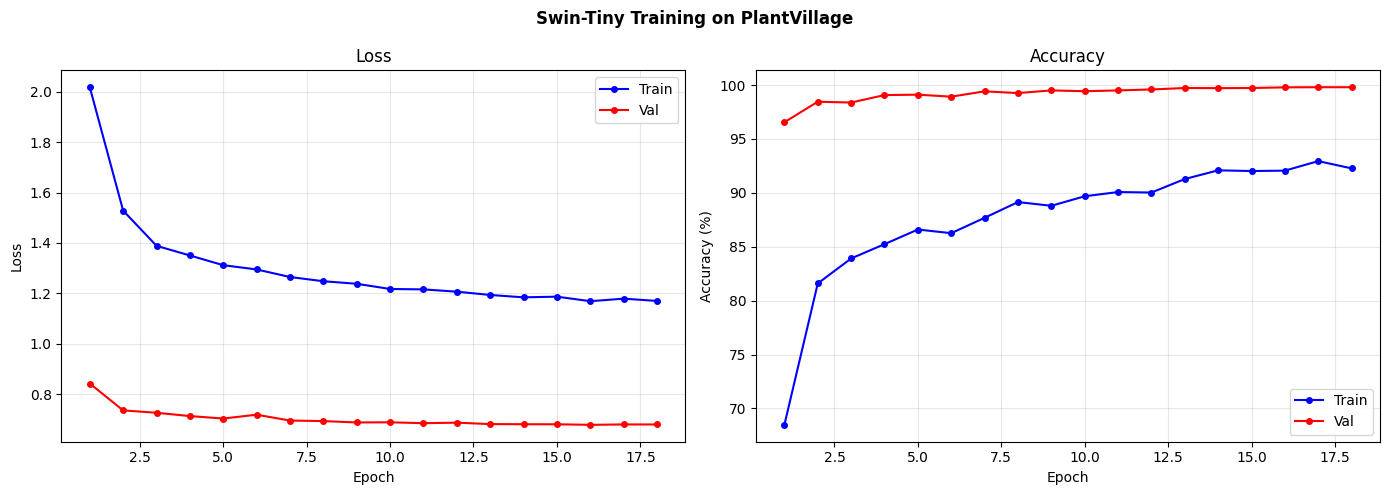

Training curves shown above & saved.


In [ ]:
# ============================================================
# CELL 5 — Train the Model
# ============================================================

# ── Mixup / CutMix ───────────────────────────────────────
mixup_fn = Mixup(
    mixup_alpha=MIXUP_ALPHA,
    cutmix_alpha=CUTMIX_ALPHA,
    prob=MIXUP_PROB,
    switch_prob=MIXUP_SWITCH_PROB,
    mode='batch',
    label_smoothing=LABEL_SMOOTHING,
    num_classes=num_classes,
)

# SoftTargetCrossEntropy handles soft labels produced by Mixup/CutMix
train_criterion = SoftTargetCrossEntropy()
val_criterion   = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

# AdamW optimizer (from paper)
optimizer = optim.AdamW(
    model.parameters(), lr=LR,
    weight_decay=WEIGHT_DECAY, betas=(0.9, 0.999)
)

# Cosine decay LR scheduler with linear warmup (from paper)
def cosine_warmup_lambda(epoch):
    if epoch < WARMUP_EPOCHS:
        return (epoch + 1) / WARMUP_EPOCHS
    progress = (epoch - WARMUP_EPOCHS) / (NUM_EPOCHS - WARMUP_EPOCHS)
    return max(0.5 * (1 + np.cos(np.pi * progress)), 1e-6 / LR)

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, cosine_warmup_lambda)

# ── Helper functions ──────────────────────────────────────────────────────────
def train_one_epoch(epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{NUM_EPOCHS} [Train]",
                leave=True)

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        # Apply Mixup / CutMix
        images, labels = mixup_fn(images, labels)

        optimizer.zero_grad()
        outputs = model(images)
        loss    = train_criterion(outputs, labels)
        loss.backward()

        # Gradient clipping (max norm = 1, from paper)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        hard  = labels.argmax(dim=1)          # hard label from soft targets
        correct += (preds == hard).sum().item()
        total   += hard.size(0)
        loop.set_postfix(loss=f"{loss.item():.3f}",
                         acc=f"{100*correct/total:.1f}%")

    return total_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(loader, split='Val'):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss    = val_criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        correct    += (outputs.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / total, 100.0 * correct / total


# ── Training loop ─────────────────────────────────────────────────────────────
history      = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
best_val_acc = 0.0
best_ckpt    = os.path.join(CKPT_DIR, 'swin_best.pth')
start_time   = time.time()

# --- EARLY STOPPING SETUP ---
patience = 7
epochs_without_improvement = 0

print(f"Starting training for {NUM_EPOCHS} epochs on {device} …\n")

for epoch in range(NUM_EPOCHS):
    t_loss, t_acc = train_one_epoch(epoch)
    v_loss, v_acc = evaluate(val_loader, 'Val')
    scheduler.step()
    lr_now = optimizer.param_groups[0]['lr']

    history['train_loss'].append(t_loss)
    history['train_acc'].append(t_acc)
    history['val_loss'].append(v_loss)
    history['val_acc'].append(v_acc)

    flag = ''
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        epochs_without_improvement = 0  # Reset counter if accuracy improves

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': best_val_acc,
            'class_names': class_names,
            'num_classes': num_classes,
        }, best_ckpt)
        flag = '   best saved'
    else:
        epochs_without_improvement += 1  # Increment counter if no improvement

    print(f"  → LR={lr_now:.2e} | "
          f"Val Loss={v_loss:.4f}  Val Acc={v_acc:.2f}%{flag}")

    # --- EARLY STOPPING TRIGGER ---
    if epochs_without_improvement >= patience:
        print(f"\n Early stopping triggered! Validation accuracy has not improved for {patience} epochs.")
        break

elapsed = time.time() - start_time
print(f"\n  Training time : {elapsed/60:.1f} minutes")
print(f" Best Val Acc  : {best_val_acc:.2f}%")
print(f"   Checkpoint    : {best_ckpt}")

with open(os.path.join(WORK_DIR, 'training_history.json'), 'w') as f:
    json.dump(history, f, indent=2)

# ── Plot training curves ──────────────────────────────────────────────────────
# Update: Dynamic epochs_range to account for early stopping
actual_epochs = len(history['train_loss'])
epochs_range = range(1, actual_epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, history['train_loss'], 'b-o', ms=4, label='Train')
ax1.plot(epochs_range, history['val_loss'],   'r-o', ms=4, label='Val')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss'); ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, history['train_acc'], 'b-o', ms=4, label='Train')
ax2.plot(epochs_range, history['val_acc'],   'r-o', ms=4, label='Val')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Accuracy'); ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle('Swin-Tiny Training on PlantVillage', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, 'training_curves.png'), dpi=120, bbox_inches='tight')
plt.show()
print("Training curves shown above & saved.")

Loaded best checkpoint (epoch 17, val_acc=99.80%)



Testing: 100%|██████████| 128/128 [00:38<00:00,  3.33it/s]


Classification Report:

                                      precision    recall  f1-score   support

                          Apple scab     1.0000    1.0000    1.0000        95
                           Black rot     1.0000    1.0000    1.0000        94
                    Cedar apple rust     1.0000    1.0000    1.0000        42
                             healthy     1.0000    1.0000    1.0000       248
                             healthy     1.0000    1.0000    1.0000       226
                      Powdery mildew     1.0000    1.0000    1.0000       159
                             healthy     1.0000    1.0000    1.0000       129
 Cercospora leaf spot Gray leaf spot     0.9868    0.9615    0.9740        78
                        Common rust      0.9945    1.0000    0.9972       180
                Northern Leaf Blight     0.9800    0.9866    0.9833       149
                             healthy     1.0000    1.0000    1.0000       175
                           Black rot   

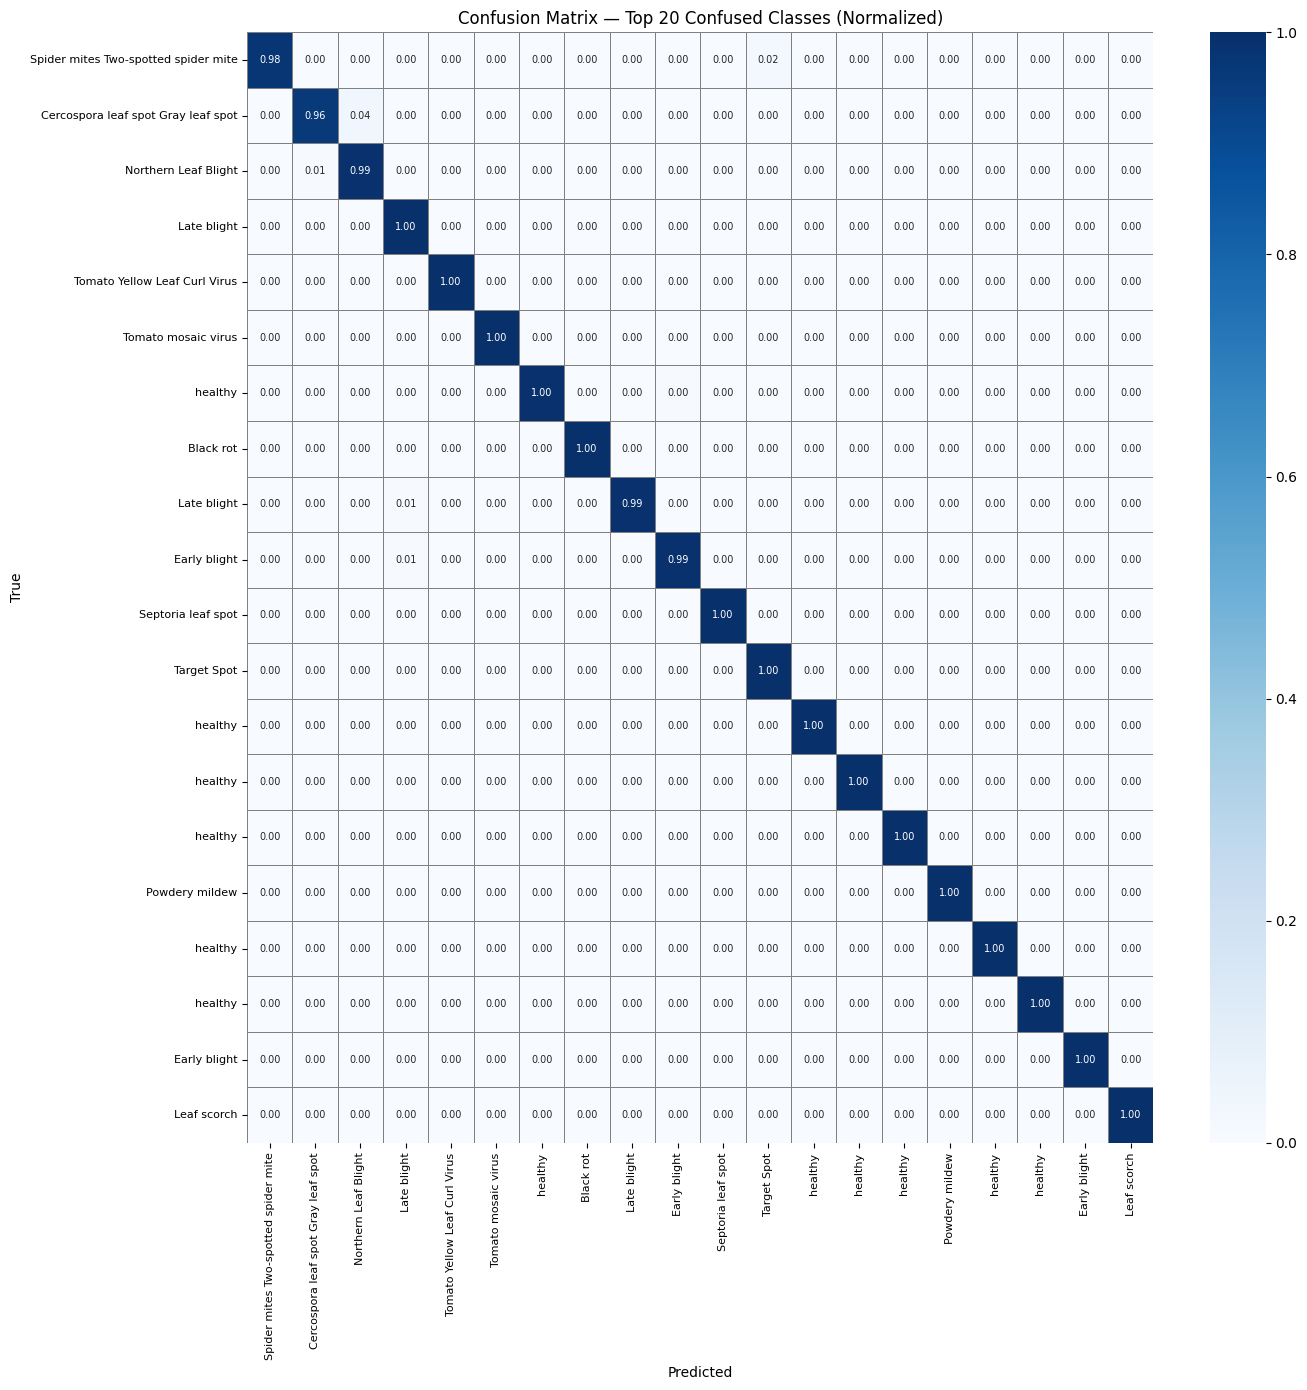

Confusion matrix generated.


In [ ]:
# ============================================================
# CELL 6 — FINAL Test Evaluation + Metrics + Confusion Matrix
# ============================================================

# ---- Load best checkpoint (FIXED) ----
ckpt = torch.load(best_ckpt, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])

print(f"Loaded best checkpoint (epoch {ckpt['epoch']}, "
      f"val_acc={ckpt['val_acc']:.2f}%)\n")

# ---- Predict on test set ----
@torch.no_grad()
def predict_test():
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device)

        outputs = model(images)
        probs   = torch.softmax(outputs, dim=1).cpu().numpy()
        preds   = outputs.argmax(dim=1).cpu().numpy()

        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

    return (np.array(all_labels),
            np.array(all_preds),
            np.array(all_probs))

labels, preds, probs = predict_test()

# ---- Metrics ----
top1 = accuracy_score(labels, preds) * 100
top5 = top_k_accuracy_score(labels, probs, k=min(5, num_classes)) * 100

short_names = [c.split('___')[-1].replace('_', ' ') for c in class_names]

# Full report
report = classification_report(labels, preds, target_names=short_names, digits=4)
print("Classification Report:\n")
print(report)

# Extract clean summary metrics
report_dict = classification_report(labels, preds,
                                    target_names=short_names,
                                    output_dict=True)

precision = report_dict['macro avg']['precision']
recall    = report_dict['macro avg']['recall']
f1        = report_dict['macro avg']['f1-score']

print(f"{'='*50}")
print(" FINAL TEST METRICS")
print(f"{'='*50}")
print(f"Accuracy  : {top1:.2f}%")
print(f"Top-5 Acc : {top5:.2f}%")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"{'='*50}")

# ---- Confusion Matrix ----
cm = confusion_matrix(labels, preds)

TOP_N = 20

if num_classes > TOP_N:
    errors  = cm.sum(axis=1) - np.diag(cm)
    top_idx = np.argsort(errors)[-TOP_N:][::-1]

    cm_plot = cm[np.ix_(top_idx, top_idx)]
    tick_labels = [short_names[i] for i in top_idx]
    title = f'Confusion Matrix — Top {TOP_N} Confused Classes'
else:
    cm_plot = cm
    tick_labels = short_names
    title = 'Confusion Matrix'

# Normalize
cm_norm = cm_plot.astype(float) / (cm_plot.sum(axis=1, keepdims=True) + 1e-9)

# Plot
fig_size = max(12, len(tick_labels) * 0.7)

plt.figure(figsize=(fig_size, fig_size))

sns.heatmap(
    cm_norm,
    annot=True,              # ✅ show numbers
    fmt=".2f",
    cmap="Blues",
    xticklabels=tick_labels,
    yticklabels=tick_labels,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"size": 7}
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(title + " (Normalized)")

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "confusion_matrix.png"),
            dpi=300, bbox_inches="tight")

plt.show()

print("Confusion matrix generated.")

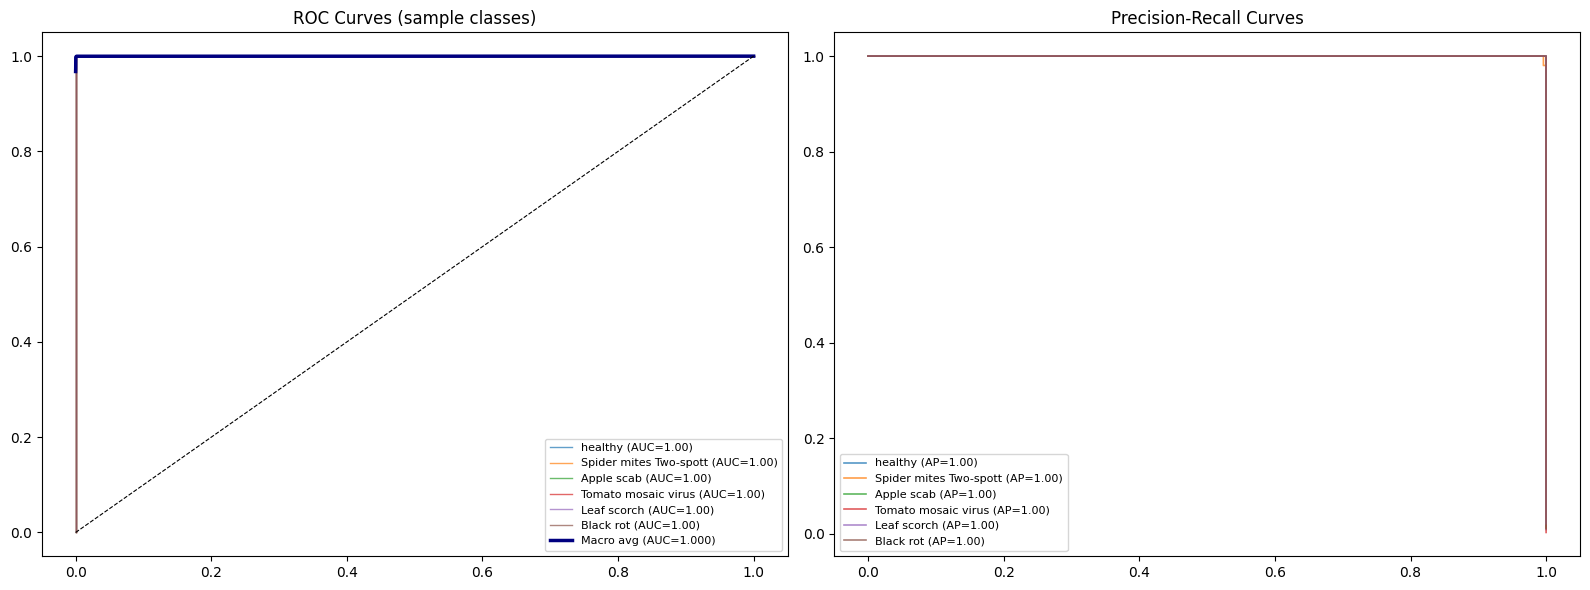

In [ ]:
# ============================================================
# CELL 7 — ROC Curves & Precision-Recall Curves (OvR)
# ============================================================
y_bin = label_binarize(all_labels, classes=range(num_classes))
fpr_dict, tpr_dict, roc_auc_dict = {}, {}, {}

for i in range(num_classes):
    fpr_dict[i], tpr_dict[i], _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc_dict[i] = auc(fpr_dict[i], tpr_dict[i])

all_fpr = np.unique(np.concatenate([fpr_dict[i] for i in range(num_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(num_classes):
    mean_tpr += np.interp(all_fpr, fpr_dict[i], tpr_dict[i])
mean_tpr /= num_classes
macro_auc = auc(all_fpr, mean_tpr)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot subset of ROC curves
sample_classes = np.random.choice(num_classes, 6, replace=False)
for i in sample_classes:
    short = class_names[i].split('___')[-1].replace('_', ' ')[:22]
    axes[0].plot(fpr_dict[i], tpr_dict[i], lw=1, alpha=0.7, label=f"{short} (AUC={roc_auc_dict[i]:.2f})")
axes[0].plot(all_fpr, mean_tpr, color='navy', lw=2.5, label=f"Macro avg (AUC={macro_auc:.3f})")
axes[0].plot([0,1],[0,1],'k--', lw=0.8)
axes[0].set_title('ROC Curves (sample classes)'); axes[0].legend(fontsize=8)

# PR Curves
for i in sample_classes:
    prec, rec, _ = precision_recall_curve(y_bin[:, i], all_probs[:, i])
    short = class_names[i].split('___')[-1].replace('_', ' ')[:22]
    axes[1].plot(rec, prec, lw=1.2, alpha=0.75, label=f"{short} (AP={auc(rec, prec):.2f})")
axes[1].set_title('Precision-Recall Curves'); axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, 'roc_pr_curves.png'))
plt.show()

 Throughput: 30.7 FPS | Parameters: 27.5 M


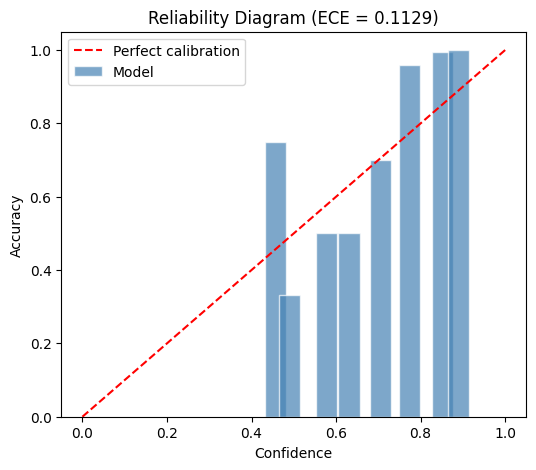

In [ ]:
# ============================================================
# CELL 8 — Inference Benchmark & Reliability Diagram
# ============================================================
model.eval()
dummy = torch.randn(1, 3, 224, 224).to(device)

t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(200): model(dummy)
elapsed = time.perf_counter() - t0

fps = 1000 / (elapsed / 200 * 1000)
print(f" Throughput: {fps:.1f} FPS | Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f} M")

# Reliability (Calibration) Diagram
confidences = all_probs.max(axis=1)
correct = (all_preds == all_labels).astype(float)
bins = np.linspace(0, 1, 16)
bin_acc, bin_conf, bin_count = [], [], []

for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (confidences >= lo) & (confidences < hi)
    if mask.sum() > 0:
        bin_acc.append(correct[mask].mean())
        bin_conf.append(confidences[mask].mean())
        bin_count.append(mask.sum())

ece = sum(cnt * abs(a - c) for a, c, cnt in zip(bin_acc, bin_conf, bin_count)) / len(all_labels)

plt.figure(figsize=(6, 5))
plt.bar(bin_conf, bin_acc, width=0.05, alpha=0.7, color='steelblue', label='Model', edgecolor='white')
plt.plot([0,1],[0,1],'r--', lw=1.5, label='Perfect calibration')
plt.title(f'Reliability Diagram (ECE = {ece:.4f})')
plt.xlabel('Confidence'); plt.ylabel('Accuracy')
plt.legend(); plt.show()

Extracting features for t-SNE...
Collected 1122 samples
Using perplexity = 30


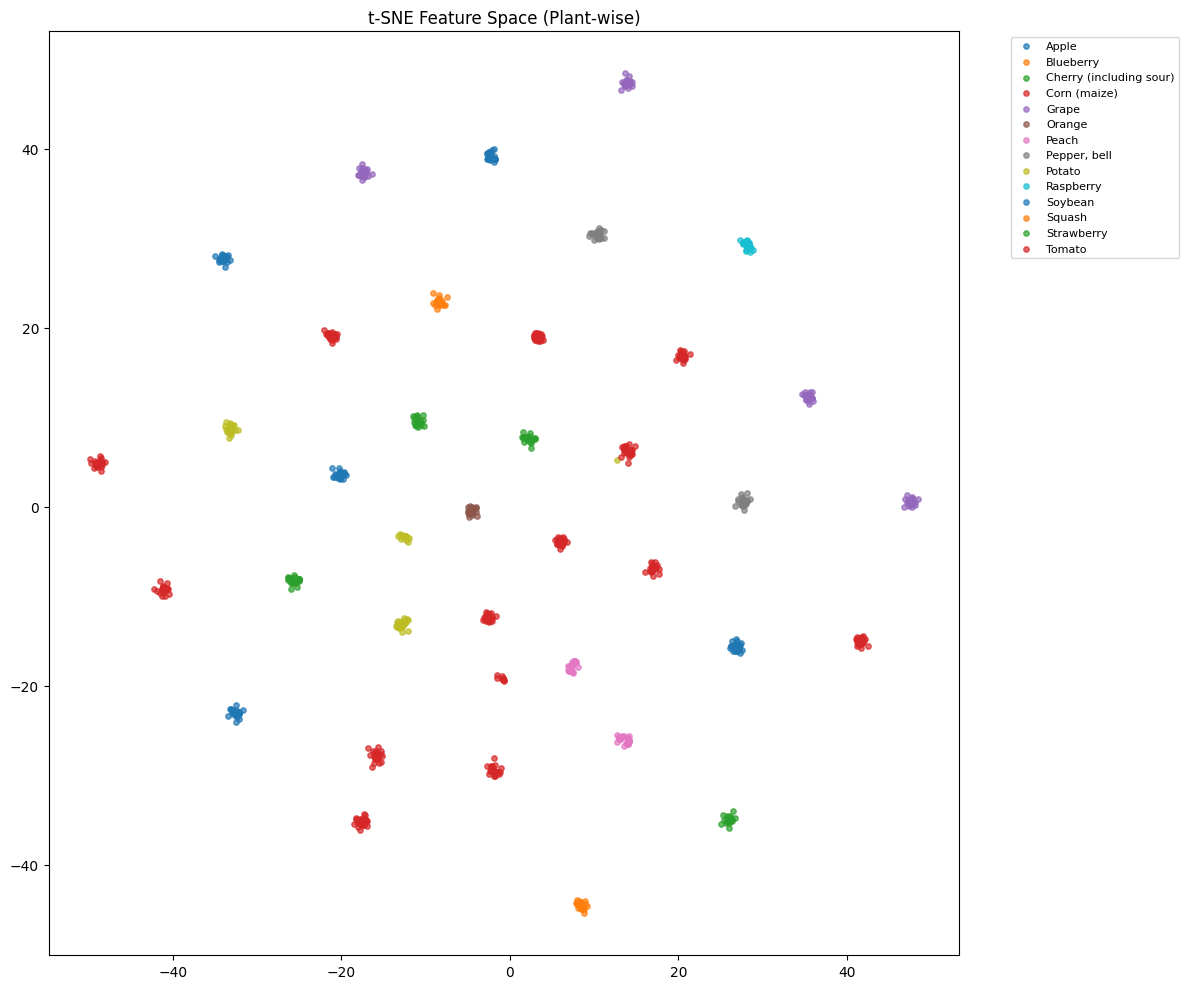

t-SNE completed successfully.


In [ ]:
# ============================================================
# CELL 9 — t-SNE Feature Space Visualization (FINAL)
# ============================================================

print("Extracting features for t-SNE...")

from collections import defaultdict
from sklearn.manifold import TSNE

features_list = []
subset_imgs, subset_lbls = [], []
class_counts = defaultdict(int)

TARGET_PER_CLASS = 30

# ---- Sampling ----
for imgs, lbls in test_loader:
    for img, lbl in zip(imgs, lbls):
        l = lbl.item()
        if class_counts[l] < TARGET_PER_CLASS:
            subset_imgs.append(img)
            subset_lbls.append(l)
            class_counts[l] += 1

    if len(subset_imgs) >= TARGET_PER_CLASS * num_classes:
        break

print(f"Collected {len(subset_imgs)} samples")

# ---- Feature extraction (Swin correct) ----
model.eval()

with torch.no_grad():
    for i in range(0, len(subset_imgs), 64):
        batch = torch.stack(subset_imgs[i:i+64]).to(device)
        feats = model.forward_features(batch)   # ✅ transformer features
        features_list.append(feats.cpu())

# ---- Convert + FIX SHAPE ----
feats = torch.cat(features_list)

# 🔴 CRITICAL FIX: flatten to 2D
feats = feats.view(feats.size(0), -1).numpy()

lbls = np.array(subset_lbls)

# ---- t-SNE params (SAFE) ----
n_samples = feats.shape[0]
perplexity = min(30, max(5, n_samples // 3))

print(f"Using perplexity = {perplexity}")

# ---- Run t-SNE ----
emb = TSNE(
    n_components=2,
    perplexity=perplexity,
    max_iter=1000,
    random_state=42
).fit_transform(feats)

# ---- Plot ----
plants = [class_names[l].split('___')[0].replace('_', ' ') for l in lbls]
unique_plants = sorted(set(plants))

plt.figure(figsize=(12, 10))

for plant in unique_plants:
    mask = np.array([p == plant for p in plants])
    plt.scatter(
        emb[mask, 0],
        emb[mask, 1],
        s=15,
        alpha=0.7,
        label=plant
    )

plt.legend(fontsize=8, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('t-SNE Feature Space (Plant-wise)')
plt.tight_layout()
plt.show()

print("t-SNE completed successfully.")

In [ ]:
# ============================================================
# CELL 12 — Save All Results to Google Drive
# ============================================================
DRIVE_OUTPUT_DIR = '/content/drive/MyDrive/swin_plantvillage_FINAL'
os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)

# Copy the best weights and classes map
shutil.copy2(best_ckpt, os.path.join(DRIVE_OUTPUT_DIR, 'swin_best.pth'))
shutil.copy2(os.path.join(WORK_DIR, 'classes.json'), os.path.join(DRIVE_OUTPUT_DIR, 'classes.json'))

# Copy generated images
for file in os.listdir(WORK_DIR):
    if file.endswith('.png'):
        shutil.copy2(os.path.join(WORK_DIR, file), os.path.join(DRIVE_OUTPUT_DIR, file))

print(f" Project saved safely to: {DRIVE_OUTPUT_DIR}")

 Project saved safely to: /content/drive/MyDrive/swin_plantvillage_FINAL
